# TP1 — Parte I | EPH 2026-T1
Predicción de informalidad con **15 variables originales**, variables familiares y preparación reproducible.

## 0.1. Librerías
Paquetes para limpieza, descripción, visualización y preparación de los datos.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from os.path import join
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.linalg import qr

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

## 0.2. Rutas
Se busca la carpeta `TP_01` a partir del directorio de trabajo, sin rutas personales.

In [2]:
# Buscar TP_01 desde el directorio actual o desde alguna de sus carpetas superiores.
carpetas = [Path.cwd(), *Path.cwd().parents]
candidatas = carpetas + [p / "TP_01" for p in carpetas]
main_path = next(
    (p for p in candidatas if (p / "A_Inputs" / "usu_individual_T126.txt").is_file()),
    None
)
if main_path is None:
    raise FileNotFoundError("No se encontró TP_01/A_Inputs. Abrir el repositorio en VS Code.")

# Carpetas del proyecto.
a_path = join(main_path, "A_Inputs")
b_path = join(main_path, "B_Outputs")
c_path = join(main_path, "C_Programs")
b_path_data = join(b_path, "B_Data")
b_path_figr = join(b_path, "B_Figure")
b_path_tabl = join(b_path, "B_Table")

print("Carpeta del TP:", main_path.resolve())

Carpeta del TP: C:\Users\alvar\OneDrive\Documentos\Mis documentos\Maestría\Economía - UdeSA\Big data\PE1333_Grupo8\TP_01


## 0.3. Lectura de datos
Se cargan las bases individual y de hogares; los códigos CNO se leen como texto.

In [3]:
datos_indiv_raw = pd.read_csv(
    join(a_path, "usu_individual_T126.txt"), sep=";", encoding="utf-8",
    low_memory=False, dtype={"PP04D_COD": "string"}
)
datos_hogar_raw = pd.read_csv(
    join(a_path, "usu_hogar_T126.txt"), sep=";", encoding="utf-8", low_memory=False
)
print("Personas:", len(datos_indiv_raw), "| Hogares:", len(datos_hogar_raw))

Personas: 43739 | Hogares: 15447


# 1. Selección y limpieza
Se consideran los ocupados con situación de formalidad identificada en `EMPLEO`.

In [4]:
# Conservar ocupados con clasificación válida
datos_indiv = datos_indiv_raw.loc[
    (datos_indiv_raw["ESTADO"] == 1) &
    (datos_indiv_raw["EMPLEO"].isin([1, 2]))
].copy()

# Variable dependiente: 1 = informal, 0 = formal
datos_indiv["informal"] = (
    datos_indiv["EMPLEO"].map({1: 0, 2: 1}).astype(int)
)

print("Observaciones:", len(datos_indiv))
print(datos_indiv["informal"].value_counts())

Observaciones: 19560
informal
0    10762
1     8798
Name: count, dtype: int64


## 1.2. Selección de variables
Quince variables originales de la EPH, sin identificadores personales ni variables utilizadas directamente para definir la informalidad.

In [5]:
# Quince variables originales seleccionadas
variables_demograficas = ["CH03", "CH04", "CH06", "CH07", "CH15", "CH16"]
variables_educacion = ["NIVEL_ED"]
variables_laborales = ["INTENSI", "PP04A", "PP04C", "P21"]
variables_geograficas = ["REGION", "MAS_500"]
variables_hogar = ["IX_MEN10", "II7"]
variables_fuente = (variables_demograficas + variables_educacion
                    + variables_laborales + variables_geograficas + variables_hogar)
assert len(variables_fuente) == 15 and len(set(variables_fuente)) == 15
assert set(variables_fuente) - set(variables_hogar) <= set(datos_indiv.columns)
print("Variables EPH seleccionadas:", len(variables_fuente))
print(variables_fuente)

Variables EPH seleccionadas: 15
['CH03', 'CH04', 'CH06', 'CH07', 'CH15', 'CH16', 'NIVEL_ED', 'INTENSI', 'PP04A', 'PP04C', 'P21', 'REGION', 'MAS_500', 'IX_MEN10', 'II7']


## 1.3. Códigos de no respuesta
Se usan los valores indicados para cada variable en el Diseño de Registro EPH 2026; el 9 no es faltante universal.

In [6]:
print("Variables originales:", len(variables_fuente))
print("Edad de 99 años:", int(datos_indiv["CH06"].eq(99).sum()))
print("Ingreso no declarado (P21=-9):", int(datos_indiv["P21"].eq(-9).sum()))
print("PP04C: no corresponde (0) / no declara (99):",
      int(datos_indiv["PP04C"].eq(0).sum()),
      int(datos_indiv["PP04C"].eq(99).sum()))
for v in ["NIVEL_ED", "INTENSI"]:
    print(f"{v}: 9 (Ns/Nr) =", int(datos_indiv[v].eq(9).sum()))


Variables originales: 15
Edad de 99 años: 1
Ingreso no declarado (P21=-9): 3719
PP04C: no corresponde (0) / no declara (99): 1314 2607
NIVEL_ED: 9 (Ns/Nr) = 0
INTENSI: 9 (Ns/Nr) = 0


## 1.4. Limpieza y recodificación
Se reemplazan los códigos de no respuesta por `NaN`. La imputación se realiza más adelante, al preparar la base de modelado.

In [7]:
# Los códigos de no respuesta dependen de la variable.
# CH06 = 99 se interpreta como faltante (CH05 = 01/01/1900 en ese registro).
datos_indiv["CH06"] = datos_indiv["CH06"].replace(99, np.nan)

for variable in ["CH15", "CH16", "NIVEL_ED", "INTENSI"]:
    datos_indiv[variable] = datos_indiv[variable].replace(9, np.nan)

# PP04C = 99 indica no respuesta; 0 significa que no corresponde.
datos_indiv["PP04C"] = datos_indiv["PP04C"].replace(99, np.nan)

# P21 = -9 indica ingreso no declarado; P21 = 0 es un ingreso cero válido.
datos_indiv["ingreso_no_declara"] = datos_indiv["P21"].eq(-9).astype(int)
datos_indiv["P21"] = datos_indiv["P21"].replace(-9, np.nan)
datos_indiv["ingreso"] = datos_indiv["P21"].copy()
assert (datos_indiv["ingreso"].dropna() >= 0).all()
datos_indiv["log_ingreso"] = np.log1p(datos_indiv["ingreso"])

print("CH06 faltantes:", int(datos_indiv["CH06"].isna().sum()))
print("PP04C faltantes:", int(datos_indiv["PP04C"].isna().sum()))
print("P21 faltantes:", int(datos_indiv["P21"].isna().sum()))

CH06 faltantes: 1
PP04C faltantes: 2607
P21 faltantes: 3719


**Fuente:** INDEC, Diseño de Registro EPH 2026. `PP04C = 99` y `P21 = -9` son no respuestas; `PP03C = 0` y `PP04C = 0` son casos no aplicables en estos datos.

## 1.5. Prevención de filtración
No se incluyen identificadores ni códigos usados directamente para definir `EMPLEO`. Se excluye `CAT_OCUP`, cuya categoría de trabajadores familiares sin remuneración forma parte de la clasificación de informalidad.

In [8]:
variables_prohibidas = [
    "EMPLEO", "SECTOR", "PP07H", "PP07I", "PP07G1", "PP07G2",
    "PP07G3", "PP07G4", "PP07G_59", "PP07K", "PP07L",
    "PP05I", "PP05J", "PP05K"
]
assert not set(variables_fuente).intersection(variables_prohibidas)
print("No se incorporan variables que definen EMPLEO.")


No se incorporan variables que definen EMPLEO.


# 2. Variables construidas
Se construyen las características del hogar. `edad2` se calcula más adelante, después de imputar `CH06` con la mediana de entrenamiento.


## 2.1. Construcción
Los identificadores de hogar se utilizan solo para agrupar registros; nunca ingresan en la matriz predictora.

In [9]:
# Características familiares: se calculan con toda la base individual.
id_hogar = ["CODUSU", "NRO_HOGAR"]
resumen_hogar = (datos_indiv_raw
    .assign(ocupado=lambda d: (d["ESTADO"] == 1).astype(int))
    .groupby(id_hogar, as_index=False)
    .agg(nhogar=("COMPONENTE", "size"), n_ocupados=("ocupado", "sum")))
resumen_hogar["prop_ocupados"] = resumen_hogar["n_ocupados"] / resumen_hogar["nhogar"]

datos_indiv = datos_indiv.merge(
    resumen_hogar[id_hogar + ["nhogar", "prop_ocupados"]],
    on=id_hogar, how="left", validate="many_to_one")

# Incorporar variables originales de hogar sin usar identificadores como predictores.
hogar_variables = datos_hogar_raw[id_hogar + ["IX_MEN10", "II7"]].copy()
datos_indiv = datos_indiv.merge(
    hogar_variables, on=id_hogar, how="left", validate="many_to_one")

# II7 = 0 no corresponde; se trata como NaN y luego se imputa con moda de train.
datos_indiv["II7"] = datos_indiv["II7"].replace(0, np.nan)
assert datos_indiv["IX_MEN10"].dropna().ge(0).all()

validacion = resumen_hogar.merge(
    datos_hogar_raw[id_hogar + ["IX_TOT"]],
    on=id_hogar, how="left", validate="one_to_one")
print("Diferencias nhogar vs IX_TOT:",
      int((validacion["nhogar"] != validacion["IX_TOT"]).sum()))

# Las variables derivadas se preparan después del split.
variables_numericas_base = [
    "CH06", "nhogar", "prop_ocupados", "log_ingreso",
    "ingreso_no_declara", "IX_MEN10"
]
variables_categoricas = [
    "CH03", "CH04", "CH07", "CH15", "CH16", "NIVEL_ED",
    "INTENSI", "PP04A", "REGION", "MAS_500", "tamano_emp", "II7"
]

print("II7 después de recodificar 0 como NaN:",
      datos_indiv["II7"].value_counts(dropna=False).to_dict())


Diferencias nhogar vs IX_TOT: 0
II7 después de recodificar 0 como NaN: {1.0: 12669, 3.0: 3753, 2.0: 1095, 6.0: 1091, 4.0: 503, 8.0: 270, 7.0: 72, 9.0: 58, 5.0: 44, nan: 5}


C:\Users\alvar\AppData\Local\Temp\ipykernel_34704\3733534845.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .assign(ocupado=lambda d: (d["ESTADO"] == 1).astype(int))


# 3. Faltantes y diferencias de medias
Primero se diagnostican los faltantes y se guarda la base pre-modelado con `NaN`. Después se divide la muestra en train y test y se preparan los predictores aprendiendo las imputaciones y categorías solo de train.


,N_faltantes,Porcentaje
P21,3719,19.013
PP04C,2607,13.328
II7,5,0.026
CH15,2,0.010
CH16,1,0.005
CH06,1,0.005


Casos con algún valor NaN: 5403
Faltantes en las variables de interés:
       N_faltantes  Porcentaje
P21           3719   19.013292
PP04C         2607   13.328221
II7              5    0.025562
CH15             2    0.010225
CH16             1    0.005112
CH06             1    0.005112
Personas con P21 y PP04C faltantes simultáneamente: 930


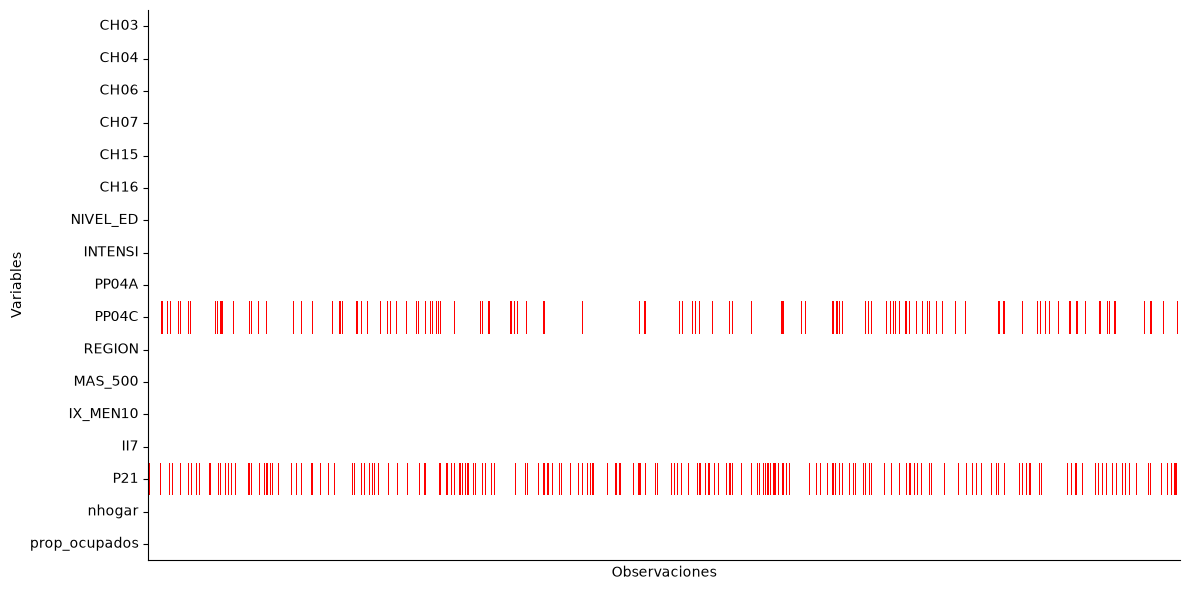

Base pre-modelado guardada: (19560, 24)


In [10]:

# -----------------------------------------------------------------------------
# Diagnóstico de faltantes ANTES de imputar o convertir PP04C en 'sin_dato'.
# Esto describe la información realmente disponible en la base depurada.
# -----------------------------------------------------------------------------

X_diagnostico = pd.DataFrame(index=datos_indiv.index)
for v in ["CH03", "CH04", "CH06", "CH07", "CH15", "CH16", "NIVEL_ED",
          "INTENSI", "PP04A", "PP04C", "REGION", "MAS_500", "IX_MEN10", "II7"]:
    X_diagnostico[v] = datos_indiv[v]

# P21 se diagnostica después de recodificar -9 como NaN.
X_diagnostico["P21"] = datos_indiv["ingreso"]

# Variables construidas que ya existen y pueden reutilizarse.
X_diagnostico["nhogar"] = datos_indiv["nhogar"]
X_diagnostico["prop_ocupados"] = datos_indiv["prop_ocupados"]

tabla_faltantes = pd.DataFrame({
    "N_faltantes": X_diagnostico.isna().sum(),
    "Porcentaje": X_diagnostico.isna().mean() * 100
}).sort_values("N_faltantes", ascending=False)

display(tabla_faltantes.loc[tabla_faltantes.N_faltantes > 0].round(3))
print("Casos con algún valor NaN:", int(X_diagnostico.isna().any(axis=1).sum()))

# Los conteos son descriptivos: se recalculan si cambia la base fuente.
print("Faltantes en las variables de interés:")
print(tabla_faltantes.loc[
    tabla_faltantes.index.intersection(["P21", "PP04C", "II7", "CH15", "CH16", "CH06"])
])

# Superposición señalada por la auditoría: no sumar faltantes por variable como individuos.
solapamiento_p21_pp04c = int(
    X_diagnostico["P21"].isna().mul(X_diagnostico["PP04C"].isna()).sum()
)
print("Personas con P21 y PP04C faltantes simultáneamente:", solapamiento_p21_pp04c)

# -----------------------------------------------------------------------------
# Heatmap de valores faltantes
# -----------------------------------------------------------------------------

plt.figure(figsize=(12, 6), facecolor="white")

ax = sns.heatmap(
    X_diagnostico.isna().T,
    cmap=["white", "red"],
    cbar=False,
    xticklabels=False,
    yticklabels=True
)

ax.set_facecolor("white")
ax.tick_params(axis="both", colors="black")

for lado in ["left", "bottom"]:
    ax.spines[lado].set_visible(True)
    ax.spines[lado].set_color("black")

for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)

plt.xlabel("Observaciones", color="black")
plt.ylabel("Variables", color="black")

plt.tight_layout()
plt.savefig(
    join(b_path_figr, "heatmap_faltantes.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

tabla_faltantes.to_csv(
    join(b_path_tabl, "tabla_faltantes.csv"), encoding="utf-8-sig"
)

# -----------------------------------------------------------------------------
# Base depurada reutilizable: conserva identificadores, variables seleccionadas
# y NaN correctamente codificados. Todavía NO hay imputación ni dummies.
# -----------------------------------------------------------------------------

columnas_premodelo = (
    id_hogar + ["COMPONENTE", "informal"] +
    [v for v in variables_fuente if v not in ["IX_MEN10", "II7"]] +
    ["IX_MEN10", "II7", "ingreso", "log_ingreso", "ingreso_no_declara",
     "nhogar", "prop_ocupados"]
)

columnas_premodelo = list(dict.fromkeys(columnas_premodelo))

base_premodelo = datos_indiv[columnas_premodelo].copy()

base_premodelo.to_csv(
    join(b_path_data, "EPH_T126_premodelo.csv"),
    index=False, encoding="utf-8-sig"
)

print("Base pre-modelado guardada:", base_premodelo.shape)

# La base pre-modelado conserva los valores faltantes de P21 y las demás variables.
assert base_premodelo["P21"].isna().sum() == base_premodelo["ingreso_no_declara"].sum()
assert base_premodelo["CH16"].isna().sum() == datos_indiv["CH16"].isna().sum()

In [11]:
# La base pre-modelado mantiene los NaN. Las transformaciones de la matriz
# de modelado se aprenden exclusivamente con la muestra de entrenamiento.
datos_modelo = datos_indiv.copy()
y_completo = datos_modelo["informal"].astype(int)

indice_train, indice_test = train_test_split(
    datos_modelo.index, train_size=.70, random_state=444
)
train_modelo = datos_modelo.loc[indice_train].copy()
test_modelo = datos_modelo.loc[indice_test].copy()

# Numéricas: medianas de train. Los valores originales no declarados de P21
# permanecen como NaN en la base pre-modelado.
mediana_edad = train_modelo["CH06"].median()
mediana_ingreso = train_modelo["P21"].median()
for datos in (train_modelo, test_modelo):
    datos["CH06"] = datos["CH06"].fillna(mediana_edad)
    datos["edad2"] = datos["CH06"] ** 2
    datos["P21"] = datos["P21"].fillna(mediana_ingreso)
    datos["ingreso"] = datos["P21"]
    datos["log_ingreso"] = np.log1p(datos["ingreso"])

# Categóricas: CH16 e II7 se imputan con la moda de train.
# Para CH15 y PP04C se conserva una categoría explícita 'sin_dato'.
moda_ch16 = train_modelo["CH16"].mode(dropna=True).iloc[0]
moda_ii7 = train_modelo["II7"].mode(dropna=True).iloc[0]
for datos in (train_modelo, test_modelo):
    datos["CH16"] = datos["CH16"].fillna(moda_ch16)
    datos["II7"] = datos["II7"].fillna(moda_ii7)
    datos["tamano_emp"] = datos["PP04C"].map(
        lambda x: "no_corresponde" if x == 0 else (
            f"tam_{int(x)}" if pd.notna(x) else "sin_dato")
    )

variables_numericas = [
    "CH06", "edad2", "nhogar", "prop_ocupados", "log_ingreso",
    "ingreso_no_declara", "IX_MEN10"
]
variables_x = variables_numericas + variables_categoricas
variables_sin_ingreso = [
    v for v in variables_x if v not in ["log_ingreso", "ingreso_no_declara", "IX_MEN10"]
]

# Cualquier otro faltante numérico se imputa también con la mediana de train.
from sklearn.impute import SimpleImputer
imputador_num = SimpleImputer(strategy="median", keep_empty_features=True)
num_train = pd.DataFrame(
    imputador_num.fit_transform(train_modelo[variables_numericas]),
    columns=variables_numericas, index=train_modelo.index)
num_test = pd.DataFrame(
    imputador_num.transform(test_modelo[variables_numericas]),
    columns=variables_numericas, index=test_modelo.index)

# Los demás faltantes categóricos se identifican con 'sin_dato'.
cat_train = train_modelo[variables_categoricas].copy()
cat_test = test_modelo[variables_categoricas].copy()
for col in variables_categoricas:
    cat_train[col] = cat_train[col].fillna("sin_dato").astype(str)
    cat_test[col] = cat_test[col].fillna("sin_dato").astype(str)

# El codificador aprende las categorías solo de entrenamiento.
try:
    encoder = OneHotEncoder(drop="first", handle_unknown="ignore",
                            sparse_output=False, dtype=float)
except TypeError:  # Compatibilidad con sklearn anterior a 1.2.
    encoder = OneHotEncoder(drop="first", handle_unknown="ignore",
                            sparse=False, dtype=float)

cat_train_arr = encoder.fit_transform(cat_train)
cat_test_arr = encoder.transform(cat_test)
cat_cols = encoder.get_feature_names_out(variables_categoricas)
cat_train_df = pd.DataFrame(cat_train_arr, columns=cat_cols, index=train_modelo.index)
cat_test_df = pd.DataFrame(cat_test_arr, columns=cat_cols, index=test_modelo.index)

X_train_base = pd.concat([num_train, cat_train_df], axis=1)
X_test_base = pd.concat([num_test, cat_test_df], axis=1)
y_train = y_completo.loc[indice_train].copy()
y_test = y_completo.loc[indice_test].copy()

assert len(X_train_base) + len(X_test_base) == len(datos_modelo)
assert len(X_train_base) == int(len(datos_modelo) * .70)
assert X_train_base.columns.equals(X_test_base.columns)
assert not X_train_base.isna().any().any() and not X_test_base.isna().any().any()
assert np.allclose(X_train_base["edad2"], X_train_base["CH06"] ** 2)
assert np.allclose(X_test_base["edad2"], X_test_base["CH06"] ** 2)

# El único NaN de CH16 está en test y recibe la moda calculada en train.
faltantes_ch16_test = datos_indiv.loc[indice_test, "CH16"].isna()
assert test_modelo.loc[faltantes_ch16_test, "CH16"].eq(moda_ch16).all()
assert not train_modelo["CH16"].isna().any() and not test_modelo["CH16"].isna().any()

print("Mediana CH06 (train):", mediana_edad)
print("Mediana P21 (train):", mediana_ingreso)
print("Moda CH16 (train):", moda_ch16, "| imputados en test:", int(faltantes_ch16_test.sum()))
print("Moda II7 (train):", moda_ii7)
print("PP04C sin_dato (train/test):",
      int((cat_train["tamano_emp"] == "sin_dato").sum()),
      int((cat_test["tamano_emp"] == "sin_dato").sum()))
print("X_train:", X_train_base.shape, "| X_test:", X_test_base.shape)

# Tabla de diferencias de medias sobre los predictores ya preparados.
X_dummies = pd.concat([X_train_base, X_test_base]).sort_index()
resultados = []
for var in X_dummies.columns:
    formales = X_dummies.loc[y_completo == 0, var].dropna().astype(float)
    informales = X_dummies.loc[y_completo == 1, var].dropna().astype(float)
    t, p = stats.ttest_ind(informales, formales, equal_var=False)
    resultados.append({
        "Variable": var,
        "Formal": formales.mean(),
        "Informal": informales.mean(),
        "Diferencia": informales.mean() - formales.mean(),
        "t_stat": t,
        "p_valor": p
    })

tabla_medias = pd.DataFrame(resultados)
print("Ocupados:", len(datos_modelo), "| Columnas transformadas:", X_dummies.shape[1])
display(tabla_medias.loc[tabla_medias.Variable.isin(
    ["CH06", "edad2", "nhogar", "prop_ocupados", "log_ingreso", "ingreso_no_declara"]
)].round(3))
tabla_medias.to_csv(
    join(b_path_tabl, "tabla_diferencia_medias_completa.csv"),
    index=False, encoding="utf-8-sig")


Mediana CH06 (train): 41.0
Mediana P21 (train): 800000.0
Moda CH16 (train): 1.0 | imputados en test: 1
Moda II7 (train): 1.0
PP04C sin_dato (train/test): 1826 781
X_train: (13692, 68) | X_test: (5868, 68)
Ocupados: 19560 | Columnas transformadas: 68


,Variable,Formal,Informal,Diferencia,t_stat,p_valor
0,CH06,43.483,39.393,-4.090,-21.487,0.000
1,edad2,2034.084,1753.447,-280.637,-16.696,0.000
2,nhogar,3.300,3.878,0.579,22.070,0.000
3,prop_ocupados,0.648,0.627,-0.021,-5.671,0.000
4,log_ingreso,13.748,12.599,-1.150,-38.133,0.000
5,ingreso_no_declara,0.198,0.180,-0.018,-3.117,0.002


## 3.3. Tablas LaTeX
Se exportan una tabla resumida y una completa para el informe.

In [12]:

# Variables seleccionadas para la tabla resumen
etiquetas = {
    "CH06": "Edad (años)",
    "edad2": "Edad al cuadrado",
    "nhogar": "Integrantes del hogar",
    "prop_ocupados": "Proporción de ocupados del hogar",
    "log_ingreso": "Logaritmo del ingreso",
    "ingreso_no_declara": "Ingreso no declarado",
    "CH15_3": "Lugar de nacimiento (categoría 3)",
    "CH16_2": "Residencia anterior (categoría 2)",
    "CH04_2": "Mujer",
    "IX_MEN10": "Menores de 10 años en el hogar",
    "II7_2.0": "Tenencia de vivienda (categoría 2)",
    "II7_3.0": "Tenencia de vivienda (categoría 3)",
    "PP04A_2": "Establecimiento (categoría 2)",
    "NIVEL_ED_6": "Nivel educativo 6"
}

# Seleccionar variables y estadísticas
base_medias = tabla_medias.set_index("Variable")

principales = [v for v in etiquetas if v in base_medias.index]
tabla_principal = base_medias.loc[principales].rename(index=etiquetas)

# Formato numérico español
def formato_es(v, dec=3):
    if pd.isna(v):
        return "--"
    return f"{v:,.{dec}f}".replace(",", "#").replace(".", ",").replace("#", ".")

# Estadístico t con estrellas
def formato_t(t, p):
    if pd.isna(t) or pd.isna(p):
        return "--"
    estrellas = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""
    return formato_es(t, 2) + (f"$^{{{estrellas}}}$" if estrellas else "")

# Generar tablas LaTeX
def exportar_tabla(tabla, nombre, etiqueta):

    lineas = [
        r"\begin{table}[H]",
        r"\centering",
        r"\caption{Diferencias de medias entre trabajadores formales e informales}",
        rf"\label{{{etiqueta}}}",
        r"\begin{tabular}{lcccc}",
        r"\toprule",
        r"Variable & Formales & Informales & Diferencia & t \\",
        r"\midrule"
    ]

    for variable, fila in tabla.iterrows():
        valores = [
            str(variable).replace("_", r"\_"),
            formato_es(fila["Formal"]),
            formato_es(fila["Informal"]),
            formato_es(fila["Diferencia"]),
            formato_t(fila["t_stat"], fila["p_valor"])
        ]
        lineas.append(" & ".join(valores) + r" \\")

    lineas += [
        r"\bottomrule",
        r"\end{tabular}",
        r"\vspace{0.2cm}",
        r"\hspace{1cm}\parbox{\linewidth}{\footnotesize\textit{Nota:} "
        r"$^{***}p<0{,}01$; $^{**}p<0{,}05$; $^{*}p<0{,}10$.}",
        r"\end{table}"
    ]

    latex = "\n".join(lineas)

    with open(join(b_path_tabl, nombre), "w", encoding="utf-8") as f:
        f.write(latex)

    return latex

# Exportar resumen y tabla completa
latex_resumen = exportar_tabla(
    tabla_principal,
    "tabla_diferencia_medias_resumen.tex",
    "tab:dif_medias_resumen"
)

latex_completa = exportar_tabla(
    base_medias,
    "tabla_diferencia_medias_completa.tex",
    "tab:dif_medias_completa"
)

print("Resumen:", len(tabla_principal), "filas")
print("Tabla completa:", len(base_medias), "filas")
print(latex_resumen)

Resumen: 11 filas
Tabla completa: 68 filas
\begin{table}[H]
\centering
\caption{Diferencias de medias entre trabajadores formales e informales}
\label{tab:dif_medias_resumen}
\begin{tabular}{lcccc}
\toprule
Variable & Formales & Informales & Diferencia & t \\
\midrule
Edad (años) & 43,483 & 39,393 & -4,090 & -21,49$^{***}$ \\
Edad al cuadrado & 2.034,084 & 1.753,447 & -280,637 & -16,70$^{***}$ \\
Integrantes del hogar & 3,300 & 3,878 & 0,579 & 22,07$^{***}$ \\
Proporción de ocupados del hogar & 0,648 & 0,627 & -0,021 & -5,67$^{***}$ \\
Logaritmo del ingreso & 13,748 & 12,599 & -1,150 & -38,13$^{***}$ \\
Ingreso no declarado & 0,198 & 0,180 & -0,018 & -3,12$^{***}$ \\
Mujer & 0,448 & 0,461 & 0,013 & 1,85$^{*}$ \\
Menores de 10 años en el hogar & 0,352 & 0,454 & 0,102 & 9,86$^{***}$ \\
Tenencia de vivienda (categoría 2) & 0,044 & 0,071 & 0,027 & 7,87$^{***}$ \\
Tenencia de vivienda (categoría 3) & 0,226 & 0,150 & -0,076 & -13,71$^{***}$ \\
Nivel educativo 6 & 0,364 & 0,090 & -0,274 & -49

# 4. Entrenamiento y prueba
La separación 70/30 con semilla 444 se realiza **antes** de aprender imputaciones o categorías. `CH06` y `P21` se imputan con medianas de train; `CH16` e `II7` con modas de train; `CH15` y `PP04C` con la categoría `sin_dato`. `OneHotEncoder` también se ajusta solo en entrenamiento.


In [13]:
# Copias para la matriz final de modelado.
X_train = X_train_base.copy()
X_test = X_test_base.copy()

# Agregar constante para los modelos que la requieren explícitamente.
X_train.insert(0, "const", 1.0)
X_test.insert(0, "const", 1.0)
assert X_train.columns.equals(X_test.columns)

# Diagnóstico de rango: no eliminar variables por su significado económico.
# Se retiran sólo columnas linealmente redundantes en la muestra de entrenamiento.
columnas = X_train.columns.tolist()
matriz = X_train.to_numpy(dtype=float)
_, R, piv = qr(matriz, mode="economic", pivoting=True)
diag = np.abs(np.diag(R))
umbral = max(matriz.shape) * np.finfo(float).eps * diag.max()
rango_inicial = int((diag > umbral).sum())
print("Rango inicial:", rango_inicial, "de", len(columnas))

seleccionadas = ["const"]
eliminadas = []
for col in columnas:
    if col == "const":
        continue
    prueba = X_train[seleccionadas + [col]].to_numpy(dtype=float)
    if np.linalg.matrix_rank(prueba, tol=1e-9) > len(seleccionadas):
        seleccionadas.append(col)
    else:
        eliminadas.append(col)

X_train = X_train[seleccionadas].copy()
X_test = X_test[seleccionadas].copy()

print("Columnas redundantes eliminadas:", eliminadas)
print("Rango final:", np.linalg.matrix_rank(X_train.to_numpy(dtype=float)),
      "de", X_train.shape[1])
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Informalidad train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))

assert X_train.columns.is_unique and X_test.columns.is_unique
assert not X_train.isna().any().any() and not X_test.isna().any().any()
assert len(X_train) + len(X_test) == len(datos_modelo)

# Diagnóstico de hogares compartidos: no modifica el split solicitado por el TP.
hogares_train = set(map(tuple, datos_modelo.loc[y_train.index, id_hogar].drop_duplicates().to_numpy()))
hogares_test = set(map(tuple, datos_modelo.loc[y_test.index, id_hogar].drop_duplicates().to_numpy()))
hogares_compartidos = hogares_train.intersection(hogares_test)

llave_hogar = list(map(tuple, datos_modelo[id_hogar].to_numpy()))
en_hogar_compartido = pd.Series(
    [h in hogares_compartidos for h in llave_hogar],
    index=datos_modelo.index
)
print("Hogares presentes en train y test:", len(hogares_compartidos))
print("Trabajadores en hogares compartidos:", int(en_hogar_compartido.sum()))

# Base final de modelado: transformada, sin NaN y con partición explícita.
base_export = pd.concat([X_train, X_test]).sort_index()
base_export["informal"] = pd.concat([y_train, y_test]).sort_index()
base_export["conjunto"] = "train"
base_export.loc[X_test.index, "conjunto"] = "test"
base_export.to_csv(
    join(b_path_data, "EPH_T126_limpia.csv"),
    index=False, encoding="utf-8-sig")

print("Base de modelado guardada:", base_export.shape)
print("Base reutilizable guardada como EPH_T126_premodelo.csv")

Rango inicial: 69 de 69
Columnas redundantes eliminadas: []
Rango final: 69 de 69
X_train: (13692, 69) | X_test: (5868, 69)
Informalidad train/test: 0.456 0.4352
Hogares presentes en train y test: 2738
Trabajadores en hogares compartidos: 6679
Base de modelado guardada: (19560, 71)
Base reutilizable guardada como EPH_T126_premodelo.csv
